# Experimento controlado: clasificador con y sin features de tópicos

Bloque 2 (modelado de tópicos con BERTopic). Machine Learning 2026/27, competición de Kaggle *Contradictory, My Dear Watson*.

Este notebook entrena el mismo clasificador del Bloque 1 con y sin el tópico de BERTopic como feature, sobre los mismos ejemplos y con la misma validación, y compara accuracy, macro-F1, matriz de confusión, curvas ROC y AUROC. Requiere haber ejecutado antes `topic_modeling.ipynb`, que genera `results_topics/topics_rows.csv`.

Datos necesarios:
- `data/train.csv`, de la competición (https://www.kaggle.com/competitions/contradictory-my-dear-watson/data);
- la partición del Bloque 1: `artifacts/splits/train.csv` y `val.csv`;
- la traducción del Bloque 1: `artifacts/translations/train_gemma3_4b.csv`.

El modelo de embeddings se descarga de HuggingFace la primera vez que se ejecuta.

Para ejecutarlo, desde la raíz del repo y con el entorno `.venv`:

```
.venv\Scripts\python -m jupyter nbconvert --to notebook --execute --inplace topic_experiment.ipynb
```

Orden de ejecución del Bloque 2: `topic_eda.ipynb` → `topic_modeling.ipynb` → `topic_experiment.ipynb`.
Semilla: `SEED = 42` en todo. Las versiones de los paquetes se imprimen en la primera celda de código.

In [1]:
import sys, platform, importlib.metadata as md
SEED = 42
def versiones(paquetes):
    filas = [("python", platform.python_version())]
    for p in paquetes:
        try:
            filas.append((p, md.version(p)))
        except md.PackageNotFoundError:
            filas.append((p, "no instalado"))
    return filas

import time, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import display
warnings.filterwarnings("ignore")

import matplotlib as mpl
import matplotlib.pyplot as plt
# Paleta categórica fija (mismo orden en todos los notebooks del Bloque 2).
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#8a5cd1", "#c23b3b"]
GRIS, GRIS_CLARO = "#8f8e88", "#d9d8d3"
COLOR_CLASE = {"entailment": PALETA[0], "neutral": PALETA[1], "contradiction": PALETA[2]}
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})

for p, v in versiones(["catboost", "scikit-learn", "spacy", "en-core-web-sm", "nltk", "scipy", "numpy", "pandas", "matplotlib"]):
    print(f"{p:16s} {v}")

python           3.11.9
catboost         1.2.10
scikit-learn     1.9.1
spacy            3.8.18
en-core-web-sm   3.8.0
nltk             3.10.4
scipy            1.17.1
numpy            2.4.6
pandas           3.1.1
matplotlib       3.11.2


## 0. Configuración del experimento (todo en esta celda)

- **Clasificador principal: CatBoost**, con la configuración final del Bloque 1 (`results_algorithms/final_config.json`, `experiment_defaults.CLASSIFIER_SPECS`): 300 árboles, profundidad 6, `learning_rate=0.1`, pérdida `MultiClass`. Secundario: Naive Bayes multinomial (`alpha=1`, `fit_prior=False`), que es rápido y sirve como segunda opinión.
- **X del Bloque 1:** texto traducido → preprocesado con spaCy (lemas, POS; las negaciones se conservan) → `pair_diff` (TF-IDF de premisa, hipótesis y su diferencia, más solapamiento léxico) + ratios POS + rasgos de relación (negaciones, longitudes, números) → `SelectKBest(chi2, k=300)`. Se construye con las mismas funciones del grupo (`parameter_variants.materialize_variants`, `training.build_pipeline`).
- **Tópicos:** las dos configuraciones de `topic_modeling.ipynb` (`topic_hdb` y `topic_km`). Así se ve si el resultado depende del algoritmo de clustering.
- Para cambiar el clasificador basta con editar `CLASIFICADORES`.

In [2]:
CLASIFICADORES = ["catboost", "naive_bayes"]        # el primero es el principal
TOPIC_COLS = {"B_hdbscan": "topic_hdb", "B_kmeans": "topic_km"}
SELECT_K = 300
N_BOOT = 1000                                         # remuestreos bootstrap para los IC
OPT = {"dtype": {"id": str}, "keep_default_na": False}
OUT = Path("results_topics"); OUT.mkdir(exist_ok=True)
LABELS = {0: "entailment", 1: "neutral", 2: "contradiction"}
CLASES = list(LABELS.values())
BRAZO_COLOR = {"A": PALETA[0], "B_hdbscan": PALETA[1], "B_kmeans": PALETA[2]}

## 1. Datos: la misma X que el Bloque 1

Se reproduce la receta del grupo (ver `JAVI_AITOR.md`, sección *Comparación histórica con traducción*). El preprocesado es fila a fila, así que no aprende nada y no puede filtrar información. Se guarda en caché en `artifacts/parameter_variants/` (la primera vez tarda ~2,5 min). Todo lo que aprende (vocabulario, IDF, selección chi²) se ajusta solo con train.

In [3]:
from parameter_variants import materialize_variants
from run_experiment_matrix import DEFAULT_CLASSIFIERS, DEFAULT_REPRESENTATIONS, load_processed_dataset
from training import build_pipeline
from classifiers import build_classifier
from sklearn.pipeline import Pipeline

english = pd.read_csv("artifacts/translations/train_gemma3_4b.csv", **OPT).set_index("id")
frames = {}
t0 = time.perf_counter()
for split in ("train", "val"):
    original = pd.read_csv(f"artifacts/splits/{split}.csv", **OPT)
    translated = english.loc[original.id].reset_index()
    pd.testing.assert_frame_equal(original, translated[original.columns])
    info, = materialize_variants(translated, variants=[{"name": "baseline", "params": {}}],
                                 base_params={"columns": ["premise_translated", "hypothesis_translated"]})
    frames[split] = load_processed_dataset(Path(info["dataset_path"]))
    assert frames[split].id.tolist() == original.id.tolist()
print(f"Preprocesado (o caché): {time.perf_counter() - t0:.1f} s | variante {info['variant_id']}")
train_df, val_df = frames["train"], frames["val"]
y_tr, y_va = train_df.label.to_numpy(), val_df.label.to_numpy()
print("train", train_df.shape, "| val", val_df.shape)

Preprocesado (o caché): 0.7 s | variante preprocess_e328b9b92d60
train (9696, 19) | val (2424, 19)


In [4]:
# Pipeline del Bloque 1. Se separa en "features + selección" y "clasificador" para poder añadir columnas.
pipe = build_pipeline(DEFAULT_REPRESENTATIONS["pair_diff"], classifier="catboost",
                      classifier_params=DEFAULT_CLASSIFIERS["catboost"], select_k=SELECT_K, random_state=SEED,
                      use_pos_features=True, use_relation_features=True)
features = Pipeline(pipe.steps[:-1])
t0 = time.perf_counter()
X_tr = sp.csr_matrix(features.fit_transform(train_df, y_tr))   # ajuste SOLO con train
X_va = sp.csr_matrix(features.transform(val_df))                # val solo se transforma
print(f"X train {X_tr.shape} | X val {X_va.shape} | {time.perf_counter() - t0:.1f} s")
print("Pasos:", [n for n, _ in pipe.steps])

X train (9696, 300) | X val (2424, 300) | 1.4 s
Pasos: ['features', 'select', 'classifier']


## 2. Features de tópico: one-hot

### 2.1. Qué podría aportar el tópico a la representación del Bloque 1 (hipótesis previa)

La X del Bloque 1 es local y léxica: qué palabras aparecen en la premisa y en la hipótesis, en qué difieren, cuánto se solapan, su composición gramatical (POS) y señales como negaciones, números o diferencia de longitud. No sabe de qué tipo de texto viene el par. El tópico añade ese contexto global, el género de la premisa (informe oficial, guía de viaje, ficción, conversación telefónica…), y podría complementar las otras features de dos maneras:
- **Modular el significado de las señales léxicas:** por ejemplo, una negación o un "I don't know" pesa distinto en una conversación transcrita (donde son muletillas) que en un informe del gobierno.
- **Capturar sesgos de anotación por género:** en algunos géneros los anotadores podrían escribir hipótesis de cierta clase de forma más reconocible.

La hipótesis nula, sugerida por la V de Cramér ≈ 0,04 de `topic_modeling.ipynb` §8, es que no aportará, porque cada premisa tiene hipótesis de las tres clases. El experimento lo comprueba.

### 2.2. Codificación

- El tópico es una categoría, no un número. "Tópico 7" no es "más" que "tópico 3", así que nunca se usa su identificador como valor numérico. Se codifica en one-hot: una columna 0/1 por tópico.
- En HDBSCAN, el −1 (outlier) es una categoría propia: "no encaja en ningún tópico" también es información.
- `OneHotEncoder(handle_unknown="ignore")` se ajusta solo con los tópicos de train. En val, un tópico que no estuviera en train daría una fila de ceros. Se comprueba en la celda siguiente que no ocurre: `transform` solo puede devolver tópicos aprendidos en train, o −1.
- Los tópicos de val vienen de `transform` (ver `topic_modeling.ipynb` §7), incluso para las premisas que también aparecen en train.
- **No se usan probabilidades de tópico**, porque K-means no las da y las dos configuraciones deben codificarse igual.
- El one-hot se añade después de la selección chi². Así la X del brazo A es exactamente la del Bloque 1 y el brazo B es esa misma X más las columnas de tópico (la selección no puede descartarlas).

In [5]:
from sklearn.preprocessing import OneHotEncoder
topics = pd.read_csv(OUT / "topics_rows.csv", **OPT).set_index("id")
T_tr, T_va = topics.loc[train_df.id], topics.loc[val_df.id]
assert (T_tr.part == "train").all() and (T_va.part == "val").all()

X = {"A": (X_tr, X_va)}
encoders = {}
for brazo, col in TOPIC_COLS.items():
    enc = OneHotEncoder(handle_unknown="ignore", dtype=np.float64)
    oh_tr = enc.fit_transform(T_tr[[col]].astype(str))
    oh_va = enc.transform(T_va[[col]].astype(str))
    nuevas = set(T_va[col]) - set(T_tr[col])
    print(f"{brazo}: {oh_tr.shape[1]} columnas one-hot | tópicos de val no vistos en train: {sorted(nuevas) or 'ninguno'}")
    X[brazo] = (sp.hstack([X_tr, oh_tr]).tocsr(), sp.hstack([X_va, oh_va]).tocsr())
    encoders[brazo] = enc
for b, (a, c) in X.items():
    print(f"  {b:10s} X train {a.shape}  X val {c.shape}")

B_hdbscan: 21 columnas one-hot | tópicos de val no vistos en train: ninguno
B_kmeans: 20 columnas one-hot | tópicos de val no vistos en train: ninguno
  A          X train (9696, 300)  X val (2424, 300)
  B_hdbscan  X train (9696, 321)  X val (2424, 321)
  B_kmeans   X train (9696, 320)  X val (2424, 320)


## 3. Entrenamiento: mismo clasificador, misma semilla y mismos hiperparámetros en cada brazo

Para cada clasificador se entrenan 3 brazos con las mismas 9.696 filas de train y se evalúan en las mismas 2.424 filas de val:
- **A:** X del Bloque 1.
- **B_hdbscan:** X + one-hot del tópico HDBSCAN.
- **B_kmeans:** X + one-hot del tópico K-means.

El clasificador se crea con la fábrica del grupo, `classifiers.build_classifier(nombre, random_state=42, hiperparámetros)`. Se guardan las probabilidades (`predict_proba`), necesarias para las curvas ROC.

In [6]:
resultados = {}   # (clasificador, brazo) -> dict con pred, proba, modelo, segundos
for clf in CLASIFICADORES:
    params = DEFAULT_CLASSIFIERS[clf]
    for brazo, (Xa, Xb) in X.items():
        modelo = build_classifier(clf, random_state=SEED, **params)
        t0 = time.perf_counter()
        modelo.fit(Xa, y_tr)
        proba = modelo.predict_proba(Xb)
        seg = time.perf_counter() - t0
        assert list(modelo.classes_) == [0, 1, 2]
        pred = proba.argmax(axis=1)
        resultados[(clf, brazo)] = {"pred": pred, "proba": proba, "modelo": modelo, "segundos": round(seg, 1)}
        print(f"{clf:12s} {brazo:10s} acc={np.mean(pred == y_va):.4f}  ({seg:.1f} s)")
print("Hiperparámetros:", json.dumps({c: DEFAULT_CLASSIFIERS[c] for c in CLASIFICADORES}))

catboost     A          acc=0.5656  (7.7 s)


catboost     B_hdbscan  acc=0.5639  (7.5 s)


catboost     B_kmeans   acc=0.5639  (7.5 s)
naive_bayes  A          acc=0.4930  (0.0 s)
naive_bayes  B_hdbscan  acc=0.4905  (0.0 s)
naive_bayes  B_kmeans   acc=0.4880  (0.0 s)
Hiperparámetros: {"catboost": {"iterations": 300, "learning_rate": 0.1, "depth": 6, "loss_function": "MultiClass", "verbose": false, "allow_writing_files": false, "thread_count": -1}, "naive_bayes": {"alpha": 1.0, "fit_prior": false}}


Comprobación de reproducibilidad: el brazo A de CatBoost debe dar la misma accuracy que el Bloque 1 con texto traducido (0,5656, `results_translation_cv/catboost_holdout.json`), y el de Naive Bayes la de `results_translation_cv/results.json` (0,4930).

In [7]:
ref_cb = json.load(open("results_translation_cv/catboost_holdout.json"))["accuracy"]
ref_nb = [e for e in json.load(open("results_translation_cv/results.json"))["experiments"]
          if e["dataset"] == "translated" and e["classifier"] == "naive_bayes"][0]["holdout"]["accuracy"]
for clf, ref in [("catboost", ref_cb), ("naive_bayes", ref_nb)]:
    if clf in CLASIFICADORES:
        acc = np.mean(resultados[(clf, "A")]["pred"] == y_va)
        print(f"{clf:12s} brazo A = {acc:.6f} | Bloque 1 = {ref:.6f} | {'REPRODUCIDO' if abs(acc - ref) < 1e-9 else 'DIFERENTE'}")

catboost     brazo A = 0.565594 | Bloque 1 = 0.565594 | REPRODUCIDO
naive_bayes  brazo A = 0.492987 | Bloque 1 = 0.492987 | REPRODUCIDO


## 4. Métricas

- **Accuracy:** % de aciertos.
- **Macro-F1:** media del F1 de las 3 clases, todas con el mismo peso.
- **Matriz de confusión:** filas = clase real, columnas = clase predicha.
- **ROC one-vs-rest:** para cada clase se convierte el problema en binario ("esta clase" frente a "las otras dos") y se dibuja la tasa de verdaderos positivos frente a la de falsos positivos al mover el umbral de la probabilidad. AUROC es el área bajo esa curva: 0,5 equivale al azar y 1 a separar perfectamente. AUROC macro es la media de las 3. Necesita probabilidades, no solo la clase predicha.
- **Métricas indefinidas:** si en un subconjunto falta alguna clase real, su AUROC no se puede calcular (no hay positivos o no hay negativos). En ese caso se deja `NaN` y el macro se calcula con las clases presentes. Aquí no ocurre en ningún subconjunto, porque las 3 clases están en todos.

In [8]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
def metricas(y, pred, proba):
    fila = {"n": len(y), "accuracy": accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, labels=[0, 1, 2], average="macro", zero_division=0)}
    aucs = []
    for c, nombre in LABELS.items():
        pos = (y == c)
        if pos.all() or (~pos).all():
            fila[f"auroc_{nombre}"] = np.nan          # indefinida: falta positivos o negativos
        else:
            fila[f"auroc_{nombre}"] = roc_auc_score(pos, proba[:, c]); aucs.append(fila[f"auroc_{nombre}"])
    fila["auroc_macro"] = np.mean(aucs) if aucs else np.nan
    return fila

seen = pd.read_csv(OUT / "val_premise_seen.csv", **OPT).set_index("id").loc[val_df.id, "premise_seen"].astype(str).eq("True").to_numpy()
SUBSETS = {"val completo": np.ones(len(y_va), bool), "premisa vista (premise_seen=True)": seen, "premisa nueva (premise_seen=False)": ~seen}
X_BASE = "texto traducido · spaCy lemas+POS · pair_diff TF-IDF (min_df=5) + ratios POS + relación · chi2 k=300"
REPRESENTACION = {"A": X_BASE, "B_hdbscan": X_BASE + " + one-hot tópico HDBSCAN (mcs=30)",
                  "B_kmeans": X_BASE + " + one-hot tópico K-means (k=20)"}
filas = []
for (clf, brazo), r in resultados.items():
    for nombre, m in SUBSETS.items():
        filas.append({"clasificador": clf, "brazo": brazo, "representacion": REPRESENTACION[brazo], "subconjunto": nombre, **metricas(y_va[m], r["pred"][m], r["proba"][m]),
                      "segundos_fit": r["segundos"]})
exp = pd.DataFrame(filas)
exp.round(4).to_csv(OUT / "experimento.csv", index=False)
fmt = {c: "{:.4f}" for c in exp.columns if c.startswith(("acc", "macro", "auroc"))}
display(exp[exp.subconjunto == "val completo"].drop(columns=["subconjunto", "representacion"]).style.format(fmt).hide(axis="index"))

clasificador,brazo,n,accuracy,macro_f1,auroc_entailment,auroc_neutral,auroc_contradiction,auroc_macro,segundos_fit
catboost,A,2424,0.5656,0.5655,0.7505,0.7397,0.7315,0.7406,7.700000
catboost,B_hdbscan,2424,0.5639,0.5638,0.7521,0.7370,0.7329,0.7407,7.500000
catboost,B_kmeans,2424,0.5639,0.5637,0.7531,0.7378,0.7329,0.7413,7.500000
naive_bayes,A,2424,0.4930,0.4900,0.6665,0.6513,0.6841,0.6673,0.000000
naive_bayes,B_hdbscan,2424,0.4905,0.4871,0.6659,0.6495,0.6833,0.6662,0.000000
naive_bayes,B_kmeans,2424,0.4880,0.4848,0.6628,0.6498,0.6830,0.6652,0.000000


### 4.1. Informe de clasificación por clase (val completo)

In [9]:
for (clf, brazo), r in resultados.items():
    print(f"===== {clf} · {brazo} =====")
    print(classification_report(y_va, r["pred"], labels=[0, 1, 2], target_names=CLASES, digits=4, zero_division=0))

===== catboost · A =====
               precision    recall  f1-score   support

   entailment     0.5772    0.5509    0.5637       835
      neutral     0.5341    0.6160    0.5721       776
contradiction     0.5915    0.5326    0.5605       813

     accuracy                         0.5656      2424
    macro avg     0.5676    0.5665    0.5655      2424
 weighted avg     0.5682    0.5656    0.5653      2424

===== catboost · B_hdbscan =====
               precision    recall  f1-score   support

   entailment     0.5850    0.5689    0.5768       835
      neutral     0.5220    0.5954    0.5563       776
contradiction     0.5915    0.5289    0.5584       813

     accuracy                         0.5639      2424
    macro avg     0.5662    0.5644    0.5638      2424
 weighted avg     0.5670    0.5639    0.5641      2424

===== catboost · B_kmeans =====
               precision    recall  f1-score   support

   entailment     0.5822    0.5725    0.5773       835
      neutral     0.525

### 4.2. Matrices de confusión

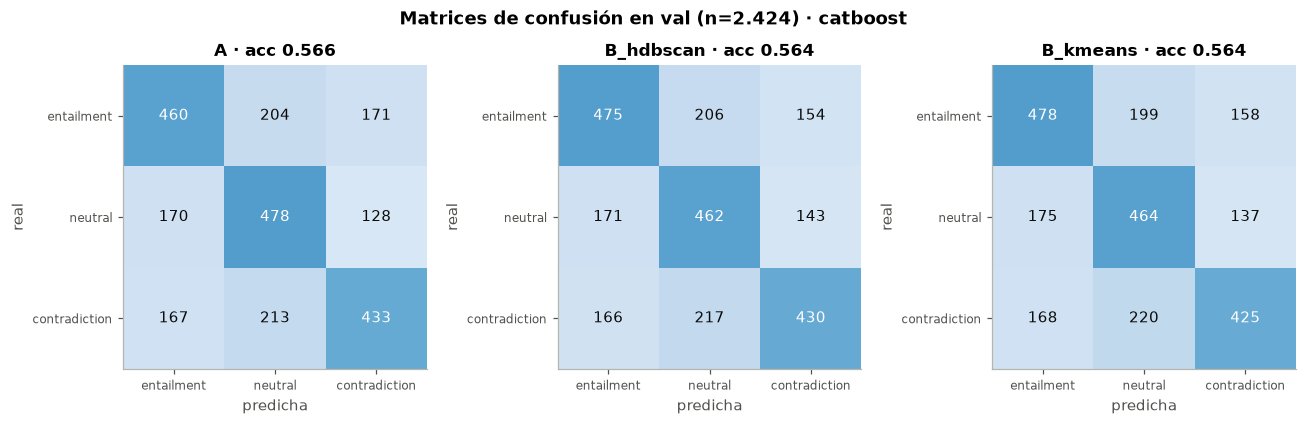

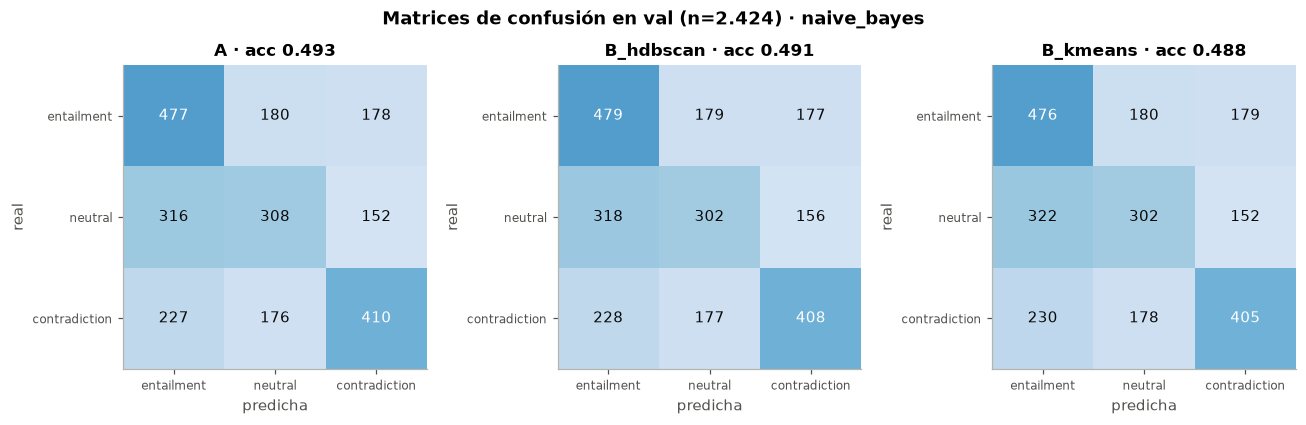

In [10]:
for clf in CLASIFICADORES:
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    for ax, brazo in zip(axes, X):
        cm = confusion_matrix(y_va, resultados[(clf, brazo)]["pred"], labels=[0, 1, 2])
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum(axis=1).max())
        for i in range(3):
            for j in range(3):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10,
                        color="white" if cm[i, j] > 0.45 * cm.sum(axis=1).max() else "#0b0b0b")
        ax.set_xticks(range(3), CLASES, fontsize=8); ax.set_yticks(range(3), CLASES, fontsize=8)
        ax.set_xlabel("predicha"); ax.set_ylabel("real"); ax.grid(False)
        ax.set_title(f"{brazo} · acc {np.trace(cm)/cm.sum():.3f}")
    fig.suptitle(f"Matrices de confusión en val (n=2.424) · {clf}", fontweight="bold"); fig.tight_layout()
    fig.savefig(OUT / f"fig_confusion_{clf}.png"); plt.show()

### 4.3. Curvas ROC one-vs-rest (una por clase, los tres brazos superpuestos)

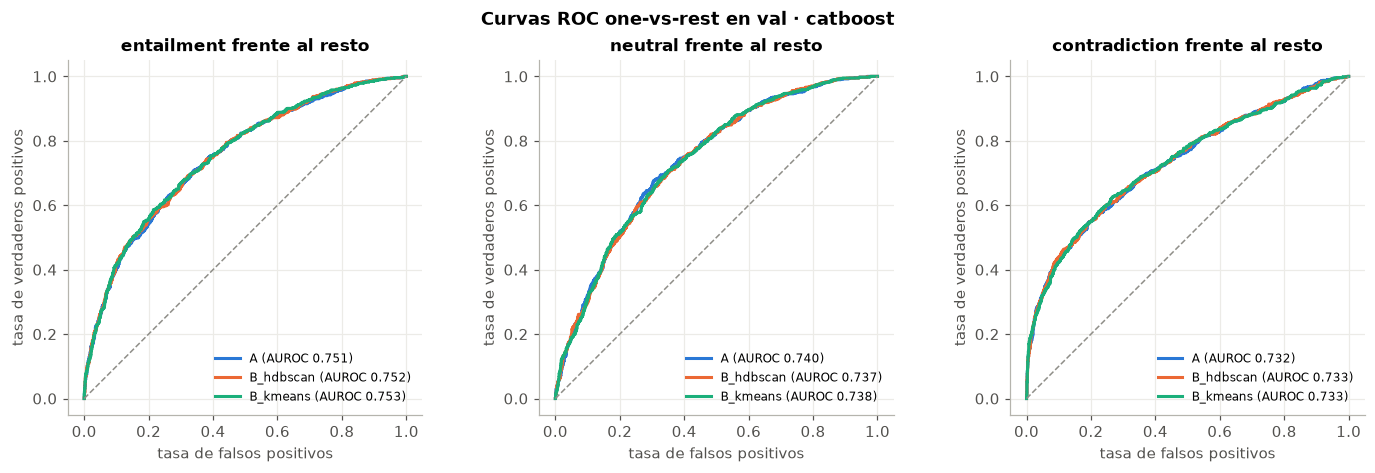

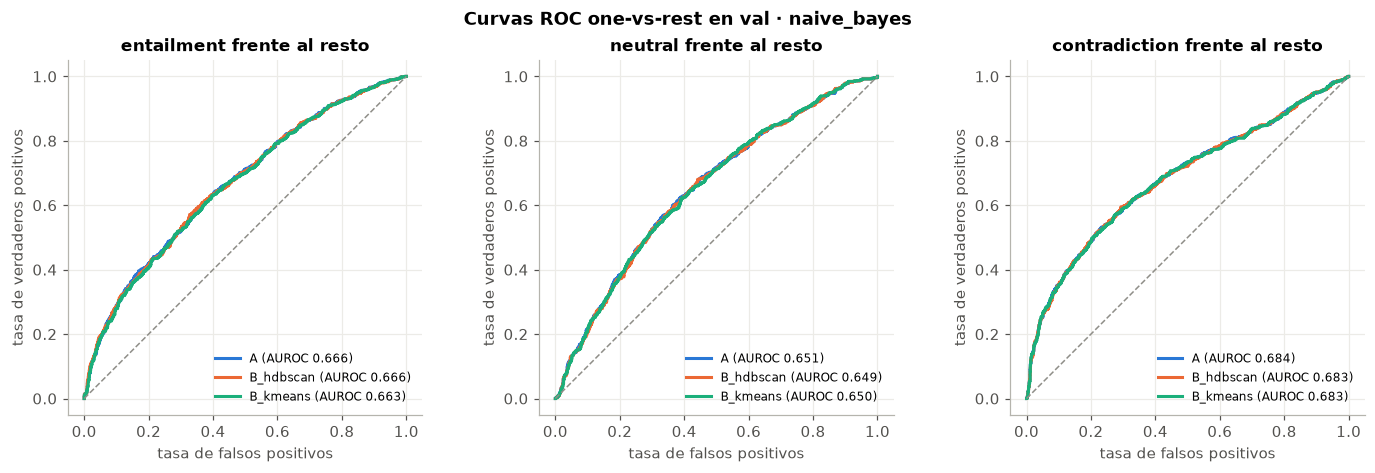

In [11]:
for clf in CLASIFICADORES:
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
    for ax, (c, nombre) in zip(axes, LABELS.items()):
        for brazo in X:
            p = resultados[(clf, brazo)]["proba"][:, c]
            fpr, tpr, _ = roc_curve(y_va == c, p)
            ax.plot(fpr, tpr, lw=2, color=BRAZO_COLOR[brazo], label=f"{brazo} (AUROC {roc_auc_score(y_va == c, p):.3f})")
        ax.plot([0, 1], [0, 1], ls="--", lw=1, color=GRIS)
        ax.set_title(f"{nombre} frente al resto"); ax.set_xlabel("tasa de falsos positivos"); ax.set_ylabel("tasa de verdaderos positivos")
        ax.set_aspect("equal"); ax.legend(loc="lower right", fontsize=8)
    fig.suptitle(f"Curvas ROC one-vs-rest en val · {clf}", fontweight="bold"); fig.tight_layout()
    fig.savefig(OUT / f"fig_roc_{clf}.png"); plt.show()

### 4.4. Métricas separando premisa vista / premisa nueva

Recordatorio (`topic_eda.ipynb` §8): 1.188 filas de val tienen una premisa que ya está en train con otra hipótesis, y 1.236 tienen una premisa nueva. Además, las vistas son casi todas inglesas.

In [12]:
piv = exp.pivot_table(index=["clasificador", "subconjunto"], columns="brazo", values=["accuracy", "macro_f1", "auroc_macro"])
display(piv.round(4))

accuracy                     \
brazo                                                  A B_hdbscan B_kmeans   
clasificador subconjunto                                                      
catboost     premisa nueva (premise_seen=False)   0.5372    0.5372   0.5380   
             premisa vista (premise_seen=True)    0.5951    0.5918   0.5909   
             val completo                         0.5656    0.5639   0.5639   
naive_bayes  premisa nueva (premise_seen=False)   0.4838    0.4822   0.4806   
             premisa vista (premise_seen=True)    0.5025    0.4992   0.4958   
             val completo                         0.4930    0.4905   0.4880   

                                                auroc_macro            \
brazo                                                     A B_hdbscan   
clasificador subconjunto                                                
catboost     premisa nueva (premise_seen=False)      0.7177    0.7191   
             premisa vista (premise_seen=True)       0.7640    0.7624   
             val completo                            0.7406    0.7407   
naive_bayes  premisa nueva (premise_seen=False)      0.6522    0.6522   
             premisa vista (premise_seen=True)       0.6810    0.6788   
             val completo                            0.6673    0.6662   

                                                         macro_f1            \
brazo                                           B_kmeans        A B_hdbscan   
clasificador subconjunto                                                      
catboost     premisa nueva (premise_seen=False)   0.7177   0.5354    0.5364   
             premisa vista (premise_seen=True)    0.7650   0.5942    0.5899   
             val completo                         0.7413   0.5655    0.5638   
naive_bayes  premisa nueva (premise_seen=False)   0.6501   0.4840    0.4824   
             premisa vista (premise_seen=True)    0.6783   0.4931    0.4886   
             val completo                         0.6652   0.4900    0.4871   

                                                          
brazo                                           B_kmeans  
clasificador subconjunto                                  
catboost     premisa nueva (premise_seen=False)   0.5370  
             premisa vista (premise_seen=True)    0.5894  
             val completo                         0.5637  
naive_bayes  premisa nueva (premise_seen=False)   0.4809  
             premisa vista (premise_seen=True)    0.4854  
             val completo                         0.4848

## 5. ¿La diferencia entre brazos es real?

Las dos pruebas usan las mismas filas de val, así que son pruebas emparejadas:
- **McNemar (exacta):** solo cuenta las filas en las que los brazos discrepan: b = A acierta y B falla, c = A falla y B acierta. Si los tópicos no aportan nada, b y c deberían ser parecidos. El p-valor sale de una prueba binomial con p = 0,5 sobre b + c.
- **Bootstrap emparejado:** se remuestrean las 2.424 filas de val con reemplazo 1.000 veces (semilla 42) y se calcula la diferencia B − A en accuracy, macro-F1 y AUROC macro. El intervalo del 95 % (percentiles 2,5–97,5) indica si la diferencia puede ser 0.

In [13]:
from scipy.stats import binomtest
rng = np.random.default_rng(SEED)
idx_boot = rng.integers(0, len(y_va), size=(N_BOOT, len(y_va)))
def auroc_macro(y, proba):
    return np.mean([roc_auc_score(y == c, proba[:, c]) for c in range(3)])
filas = []
for clf in CLASIFICADORES:
    rA = resultados[(clf, "A")]
    for brazo in TOPIC_COLS:
        rB = resultados[(clf, brazo)]
        okA, okB = rA["pred"] == y_va, rB["pred"] == y_va
        b, c = int((okA & ~okB).sum()), int((~okA & okB).sum())
        p = binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
        d_acc, d_f1, d_auc = [], [], []
        for ix in idx_boot:
            yy = y_va[ix]
            d_acc.append(okB[ix].mean() - okA[ix].mean())
            d_f1.append(f1_score(yy, rB["pred"][ix], average="macro") - f1_score(yy, rA["pred"][ix], average="macro"))
            d_auc.append(auroc_macro(yy, rB["proba"][ix]) - auroc_macro(yy, rA["proba"][ix]))
        ic = lambda v: f"[{np.percentile(v, 2.5):+.4f}, {np.percentile(v, 97.5):+.4f}]"
        filas.append({"clasificador": clf, "comparacion": f"{brazo} − A",
                      "Δaccuracy": okB.mean() - okA.mean(), "IC95_Δaccuracy": ic(d_acc),
                      "Δmacro_f1": f1_score(y_va, rB["pred"], average="macro") - f1_score(y_va, rA["pred"], average="macro"), "IC95_Δmacro_f1": ic(d_f1),
                      "Δauroc_macro": auroc_macro(y_va, rB["proba"]) - auroc_macro(y_va, rA["proba"]), "IC95_Δauroc_macro": ic(d_auc),
                      "b (A acierta, B falla)": b, "c (A falla, B acierta)": c, "p_McNemar": round(p, 4)})
pruebas = pd.DataFrame(filas)
pruebas.round(4).to_csv(OUT / "experimento_pruebas.csv", index=False)
display(pruebas.round(4))

,clasificador,comparacion,Δaccuracy,IC95_Δaccuracy,Δmacro_f1,IC95_Δmacro_f1,Δauroc_macro,IC95_Δauroc_macro,"b (A acierta, B falla)","c (A falla, B acierta)",p_McNemar
0,catboost,B_hdbscan − A,-0.0017,"[-0.0120, +0.0074]",-0.0016,"[-0.0121, +0.0078]",0.0001,"[-0.0029, +0.0030]",74,70,0.8027
1,catboost,B_kmeans − A,-0.0017,"[-0.0111, +0.0083]",-0.0017,"[-0.0109, +0.0080]",0.0007,"[-0.0023, +0.0038]",74,70,0.8027
2,naive_bayes,B_hdbscan − A,-0.0025,"[-0.0078, +0.0029]",-0.0029,"[-0.0085, +0.0026]",-0.0011,"[-0.0026, +0.0006]",25,19,0.4514
3,naive_bayes,B_kmeans − A,-0.0050,"[-0.0107, +0.0017]",-0.0052,"[-0.0113, +0.0014]",-0.0021,"[-0.0038, -0.0005]",36,24,0.1550


## 6. ¿Usa el modelo los tópicos? Importancia de las features en CatBoost

CatBoost indica cuánto contribuye cada columna a sus decisiones (`get_feature_importance`, que suma 100). Se suma la importancia de todas las columnas de tópico del brazo B.

In [14]:
if "catboost" in CLASIFICADORES:
    for brazo in TOPIC_COLS:
        imp = resultados[("catboost", brazo)]["modelo"].get_feature_importance()
        n_top = X[brazo][0].shape[1] - X_tr.shape[1]
        cols_top = imp[-n_top:]
        cats = encoders[brazo].categories_[0]
        mejores = pd.Series(cols_top, index=[f"tópico {c}" for c in cats]).sort_values(ascending=False).head(5).round(2)
        print(f"{brazo}: {n_top} columnas de tópico = {100 * n_top / len(imp):.1f} % de las columnas | "
              f"importancia total de los tópicos = {cols_top.sum():.2f} % (de 100)")
        print("   tópicos con más importancia:", mejores.to_dict())

B_hdbscan: 21 columnas de tópico = 6.5 % de las columnas | importancia total de los tópicos = 1.06 % (de 100)
   tópicos con más importancia: {'tópico 9': 0.4, 'tópico 0': 0.21, 'tópico 2': 0.14, 'tópico 3': 0.1, 'tópico 1': 0.08}
B_kmeans: 20 columnas de tópico = 6.2 % de las columnas | importancia total de los tópicos = 1.60 % (de 100)
   tópicos con más importancia: {'tópico 7': 0.76, 'tópico 0': 0.17, 'tópico 1': 0.12, 'tópico 11': 0.1, 'tópico 6': 0.07}


## 7. Errores por tópico

Tasa de error de cada brazo en cada tópico (filas de val), siempre con el número de ejemplos (n). Una diferencia en un tópico con pocas filas puede deberse a 2 o 3 ejemplos. No se calcula AUROC por tópico porque con n pequeño es muy inestable y en algunos tópicos podría faltar alguna clase.

In [15]:
NOMBRES = {c: pd.read_csv(OUT / f, keep_default_na=False).set_index("topic").nombre.to_dict()
           for c, f in [("topic_hdb", "topicos_hdbscan.csv"), ("topic_km", "topicos_kmeans.csv")]}
clf0 = CLASIFICADORES[0]
tablas_err = {}
for brazo, col in TOPIC_COLS.items():
    d = pd.DataFrame({"topic": T_va[col].to_numpy(), "seen": seen,
                      "error_A": resultados[(clf0, "A")]["pred"] != y_va,
                      f"error_{brazo}": resultados[(clf0, brazo)]["pred"] != y_va})
    t = d.groupby("topic").agg(n=("error_A", "size"), n_premisa_nueva=("seen", lambda s: int((~s).sum())),
                               error_A=("error_A", "mean"), **{f"error_{brazo}": (f"error_{brazo}", "mean")})
    t["diferencia_B_menos_A"] = t[f"error_{brazo}"] - t.error_A
    t.insert(0, "nombre", [NOMBRES[col].get(k, "?") for k in t.index])
    t = t.sort_values("n", ascending=False)
    t.round(3).to_csv(OUT / f"errores_por_topico_{col.split('_')[1]}.csv")
    tablas_err[brazo] = t
    print(f"===== {clf0}: error por tópico ({col}) ====="); display(t.round(3))

===== catboost: error por tópico (topic_hdb) =====


,nombre,n,n_premisa_nueva,error_A,error_B_hdbscan,diferencia_B_menos_A
topic,,,,,,
-1,Outliers (sin tópico),840,434,0.436,0.439,0.004
0,"Gobierno: servicios legales, programas y costes",645,317,0.389,0.386,-0.003
1,"Viajes: ciudades, playas y monumentos",273,108,0.399,0.418,0.018
2,"Ficción histórica (Lord Julian, capitán Blood)",75,47,0.453,0.493,0.040
4,Conversación: clima y vida en Texas,73,27,0.397,0.438,0.041
3,"Conversación: asentimientos (that's good, yes)",70,36,0.414,0.457,0.043
5,"Informe del 11-S (KSM, CIA, FDNY)",70,58,0.529,0.514,-0.014
7,Hijos y crianza,59,34,0.492,0.424,-0.068
6,Ficción: personajes y diálogo,56,29,0.536,0.607,0.071


===== catboost: error por tópico (topic_km) =====


,nombre,n,n_premisa_nueva,error_A,error_B_kmeans,diferencia_B_menos_A
topic,,,,,,
0,Gestión pública y agencias (informes),272,116,0.353,0.342,-0.011
2,"Costes, correo postal e impuestos",203,94,0.389,0.414,0.025
1,"Ficción histórica (Lord Julian, capitán Blood)",183,100,0.470,0.470,0.000
4,Conversación: asentimientos,158,81,0.437,0.424,-0.013
3,"Viajes: playas, islas y tiendas",136,54,0.390,0.419,0.029
7,Negación: no sé / no creo,127,61,0.551,0.551,0.000
8,"Monumentos: templos, iglesias, historia",125,45,0.408,0.408,0.000
6,"Mezcla: ciencia, ordenadores y frases sueltas",118,64,0.390,0.390,0.000
10,Conversación: clima y Texas,118,44,0.415,0.424,0.008


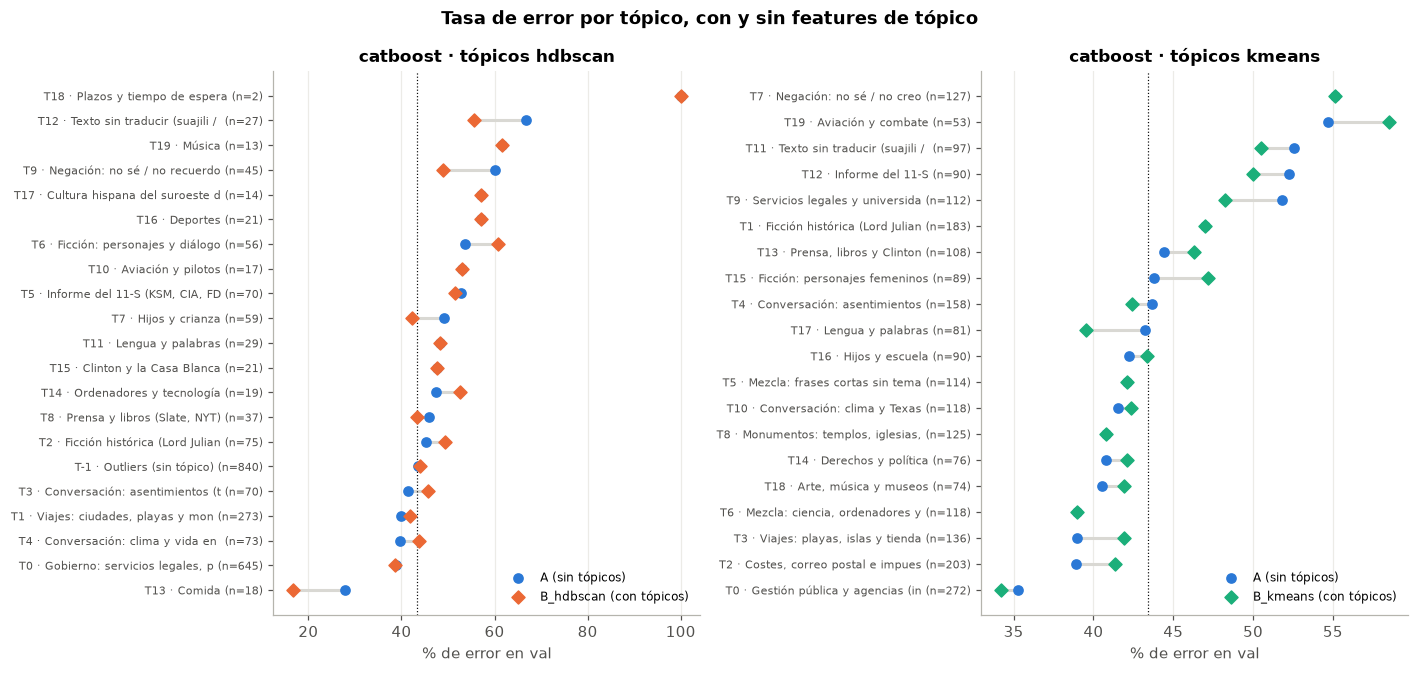

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, (brazo, t) in zip(axes, tablas_err.items()):
    t = t.sort_values("error_A")
    yy = np.arange(len(t))
    ax.hlines(yy, t.error_A * 100, t[f"error_{brazo}"] * 100, color=GRIS_CLARO, lw=2)
    ax.scatter(t.error_A * 100, yy, s=36, color=BRAZO_COLOR["A"], label="A (sin tópicos)", zorder=3)
    ax.scatter(t[f"error_{brazo}"] * 100, yy, s=36, color=BRAZO_COLOR[brazo], label=f"{brazo} (con tópicos)", zorder=3, marker="D")
    ax.set_yticks(yy, [f"T{k} · {nm[:30]} (n={n})" for k, nm, n in zip(t.index, t.nombre, t.n)], fontsize=7.5)
    ax.axvline(100 * np.mean(resultados[(clf0, "A")]["pred"] != y_va), color="#0b0b0b", lw=0.8, ls=":")
    ax.set_xlabel("% de error en val"); ax.grid(axis="y", visible=False); ax.legend(loc="lower right", fontsize=8)
    ax.set_title(f"{clf0} · tópicos {brazo.split('_')[1]}")
fig.suptitle("Tasa de error por tópico, con y sin features de tópico", fontweight="bold"); fig.tight_layout()
fig.savefig(OUT / f"fig_errores_por_topico_{clf0}.png"); plt.show()

## 8. Conclusiones y tabla de resultados

In [17]:
resumen = exp[exp.subconjunto == "val completo"][["clasificador", "brazo", "n", "accuracy", "macro_f1", "auroc_entailment", "auroc_neutral", "auroc_contradiction", "auroc_macro"]]
display(resumen.round(4).set_index(["clasificador", "brazo"]))
display(pruebas[["clasificador", "comparacion", "Δaccuracy", "IC95_Δaccuracy", "Δauroc_macro", "IC95_Δauroc_macro", "p_McNemar"]].round(4))

n  accuracy  macro_f1  auroc_entailment  \
clasificador brazo                                                   
catboost     A          2424    0.5656    0.5655            0.7505   
             B_hdbscan  2424    0.5639    0.5638            0.7521   
             B_kmeans   2424    0.5639    0.5637            0.7531   
naive_bayes  A          2424    0.4930    0.4900            0.6665   
             B_hdbscan  2424    0.4905    0.4871            0.6659   
             B_kmeans   2424    0.4880    0.4848            0.6628   

                        auroc_neutral  auroc_contradiction  auroc_macro  
clasificador brazo                                                       
catboost     A                 0.7397               0.7315       0.7406  
             B_hdbscan         0.7370               0.7329       0.7407  
             B_kmeans          0.7378               0.7329       0.7413  
naive_bayes  A                 0.6513               0.6841       0.6673  
             B_hdbscan         0.6495               0.6833       0.6662  
             B_kmeans          0.6498               0.6830       0.6652

,clasificador,comparacion,Δaccuracy,IC95_Δaccuracy,Δauroc_macro,IC95_Δauroc_macro,p_McNemar
0,catboost,B_hdbscan − A,-0.0017,"[-0.0120, +0.0074]",0.0001,"[-0.0029, +0.0030]",0.8027
1,catboost,B_kmeans − A,-0.0017,"[-0.0111, +0.0083]",0.0007,"[-0.0023, +0.0038]",0.8027
2,naive_bayes,B_hdbscan − A,-0.0025,"[-0.0078, +0.0029]",-0.0011,"[-0.0026, +0.0006]",0.4514
3,naive_bayes,B_kmeans − A,-0.0050,"[-0.0107, +0.0017]",-0.0021,"[-0.0038, -0.0005]",0.1550


Resultado: negativo, y es un resultado válido. Añadir el tópico de BERTopic como feature no mejora ninguno de los dos clasificadores:

| Clasificador | Brazo | Accuracy | Macro-F1 | AUROC macro | Δaccuracy frente a A (IC 95 %) | McNemar p |
|---|---|---:|---:|---:|---|---:|
| CatBoost | A (Bloque 1) | 0,5656 | 0,5655 | 0,7406 | — | — |
| CatBoost | B + tópico HDBSCAN | 0,5639 | 0,5638 | 0,7407 | −0,17 pp [−1,20; +0,74] | 0,80 |
| CatBoost | B + tópico K-means | 0,5639 | 0,5637 | 0,7413 | −0,17 pp [−1,11; +0,83] | 0,80 |
| Naive Bayes | A (Bloque 1) | 0,4930 | 0,4900 | 0,6673 | — | — |
| Naive Bayes | B + tópico HDBSCAN | 0,4905 | 0,4871 | 0,6662 | −0,25 pp [−0,78; +0,29] | 0,45 |
| Naive Bayes | B + tópico K-means | 0,4880 | 0,4848 | 0,6652 | −0,50 pp [−1,07; +0,17] | 0,16 |

- **Las diferencias son de décimas de punto y ninguna es significativa.** En CatBoost los brazos discrepan en unas 145 filas de 2.424, repartidas casi a partes iguales (74 frente a 70 con los dos algoritmos): el modelo "cambia de opinión" en pocos casos y sin ganar nada. Los intervalos bootstrap incluyen el 0. La única excepción es el AUROC macro de Naive Bayes con K-means, cuyo IC está entero por debajo de 0 (−0,21 puntos de AUROC), un empeoramiento real pero despreciable en la práctica.
- **CatBoost apenas usa los tópicos:** las ~20 columnas de tópico (6 % de las columnas) reciben solo un 1–1,6 % de la importancia total. La que más usa es la del tópico K-means "Negación: no sé / no creo", seguramente porque se solapa con lo que ya miden los rasgos de relación (negaciones).
- **Por qué no ayudan (argumento):**
  1. La clase NLI depende de la relación premisa–hipótesis, mientras que el tópico solo describe de qué habla la premisa.
  2. En `topic_modeling.ipynb` §8 se vio que la distribución de clases es la misma en todos los tópicos (χ² no significativo, V de Cramér ≈ 0,04). Para cada premisa hay hipótesis de las tres clases, así que saber el tópico no cambia la probabilidad de cada clase.
  3. El tópico es el mismo para todas las filas de una premisa. Esas filas tienen etiquetas distintas, así que una feature que no varía entre ellas no puede separarlas.
- **Premisa vista frente a nueva:** CatBoost acierta un 59,5 % con premisa vista y un 53,7 % con premisa nueva. La partición no agrupada infla algo la métrica global (y, como se vio en el EDA, "vista" es casi siempre "inglesa"). Los tópicos no cambian esto: la diferencia entre brazos es igual de nula en los dos subconjuntos, así que la conclusión no depende del solapamiento de premisas.
- **Errores por tópico (lo útil del Bloque 2):** aunque el tópico no sirve como feature, sí sirve para diagnosticar dónde falla el clasificador. Con K-means, el error de CatBoost va del 35 % en "Gestión pública" (n=272) al 55 % en "Negación: no sé / no creo" (n=127) y al 52 % en el informe del 11-S (n=90). Con HDBSCAN, el tópico "Texto sin traducir" tiene un 67 % de error (n=27): las premisas que no se tradujeron perjudican al modelo, que usa n-gramas en inglés. Las diferencias en tópicos con n < 30 se deben interpretar con prudencia.
- **Qué haría falta para que el tópico ayudara:** features que relacionen la premisa con la hipótesis, como si la hipótesis cae en el mismo tópico que su premisa o la similitud entre los dos embeddings. Quedan fuera del alcance de este experimento, que es el que pide el enunciado: el tópico de la premisa como feature.